## This script is used for code dubuging by executing command line by line

### 1. Depuging the  FlyFinder_first_segmentation.py  script

In [1]:

import os
from FF_utils import *

modelName="M4Panel_GF30_MF10_Es30_mar40_topG150_RFC_Andrew"  
plateType="4Panel" 
minArea= 120 
maxArea=380 
nFilters=30
margin=140
numFlies=20

minArea=120 
maxArea=380 
nGaussianFilters=30
nMedianFilters=10
bottomMargin=40
topGap=150
cropLeft=650
cropRight=750
cropTop=50 
cropBottom=150


inPath="./train_4p_Andrew/"
pathIMG=inPath
imFiles=[r for r in os.listdir(pathIMG) if (r.lower().endswith(".jpg")==True and r.lower().startswith("._")==False)]




In [3]:
imFiles

['100_fly.JPG', '100_fly_lbl.jpg']

In [5]:
imgFile=imFiles[0]
imgO_=cv2.imread(pathIMG+imgFile)

## Original image and labeled images
#imgO_=cv2.imread(pathTrain+originals[i])
#imgL_=cv2.imread(pathTrain+labeled[i])
               
# Cropping the image
imgO_=imgO_[:, 600:(imgO_.shape[1]-500),:]
imgO_=imgO_[200:(imgO_.shape[0]-100), :, :]
#imgL_=imgL_[:, args.cropLeft:(imgL_.shape[1]-args.cropRight),:]
#imgL_=imgL_[args.cropTop:(imgL_.shape[0]-args.cropBottom), :, :]
            

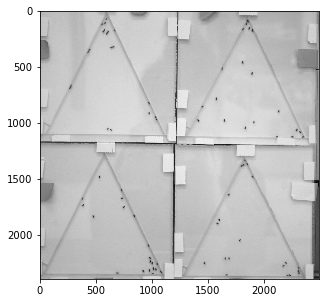

In [20]:
imgO_1=cv2.imread(pathIMG+imgFile)
                
                ## Cropping the image
imgO_1=imgO_1[:, cropLeft:(imgO_1.shape[1]-cropRight),:]
imgO_1=imgO_1[cropTop:(imgO_1.shape[0]-cropBottom), :, :]
                
imgGray_=cv2.cvtColor(imgO_1, cv2.COLOR_BGR2GRAY)
showFig(imgGray_,5)

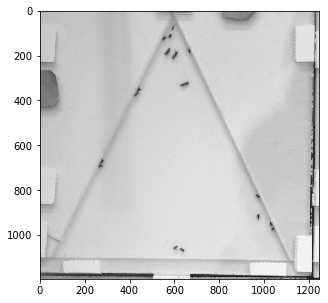

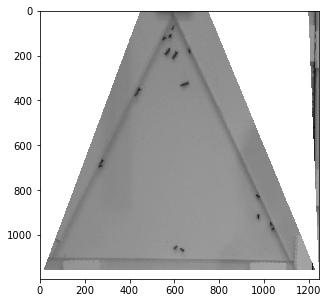

In [38]:
corr={}
corr["a"]=[0,int(imgGray_.shape[0]/2),0,int(imgGray_.shape[1]/2)]
corr["b"]=[0,int(imgGray_.shape[0]/2),int(imgGray_.shape[1]/2)+1,imgGray_.shape[1]]
corr["c"]=[int(imgGray_.shape[0]/2)+1,imgGray_.shape[0],0,int(imgGray_.shape[1]/2)]
corr["d"]=[int(imgGray_.shape[0]/2)+1,imgGray_.shape[0],int(imgGray_.shape[1]/2)+1,imgGray_.shape[1]]

panel="a"

pos=corr[panel]
                      
imgO=imgO_1[pos[0]:pos[1],pos[2]:pos[3],:]
imgGray=imgGray_[pos[0]:pos[1],pos[2]:pos[3]]

showFig(imgGray,5)
imgGray1=maskFig(imgGray,bottomMargin,topGap,255); 
showFig(imgGray1,5)

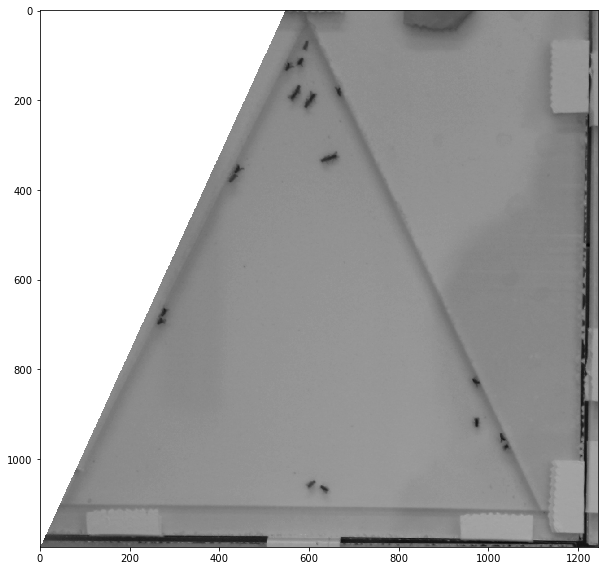

In [44]:


inpImg=imgGray.copy()
    
     
# fill polygon1
poly = np.array(( (0, 0), (0, int(inpImg.shape[1]/2)- int(topGap/2)), (inpImg.shape[0], 0)))
rr, cc = polygon(poly[:,0], poly[:,1], inpImg.shape)
inpImg[rr,cc] = 255
showFig(inpImg)

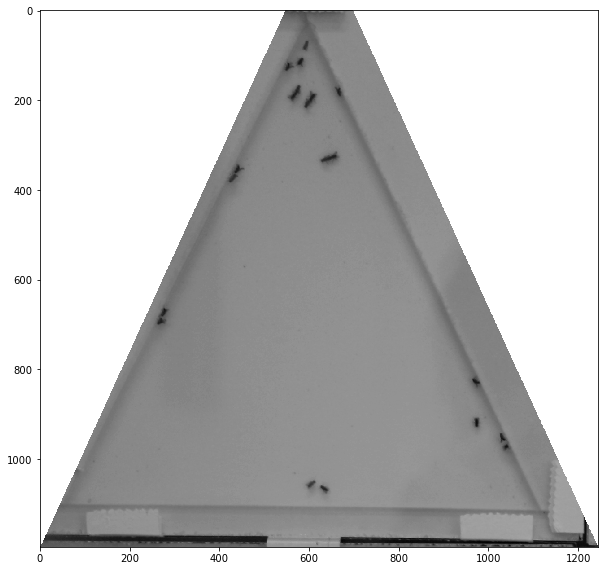

In [45]:
    
# fill polygon2
poly = np.array(( (0,int(inpImg.shape[1]/2)+int(topGap/2)), (0,inpImg.shape[1]), (inpImg.shape[0],inpImg.shape[1])))
rr, cc = polygon(poly[:,0], poly[:,1], inpImg.shape)
inpImg[rr,cc] = 255
showFig(inpImg)

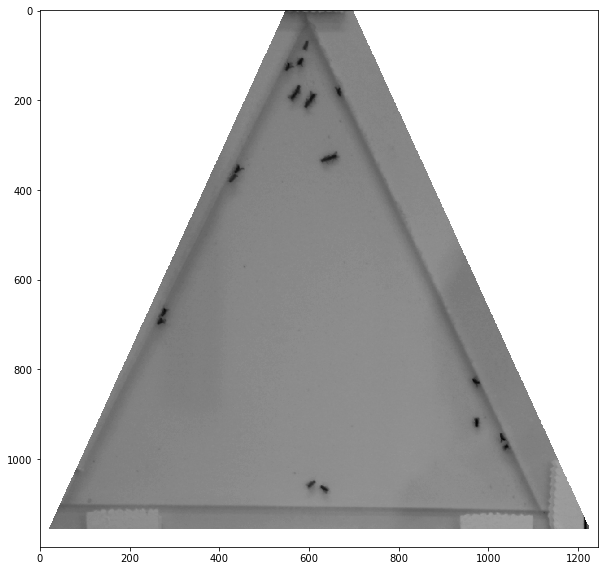

In [50]:
# fill polygon3
poly = np.array((( inpImg.shape[0]-bottomMargin,0), (inpImg.shape[0],0),(inpImg.shape[0],inpImg.shape[1]), (inpImg.shape[0]-bottomMargin,inpImg.shape[1]) ))
rr, cc = polygon(poly[:,0], poly[:,1], inpImg.shape)
inpImg[rr,cc] = 255
showFig(inpImg)

TypeError: Invalid shape (4,) for image data

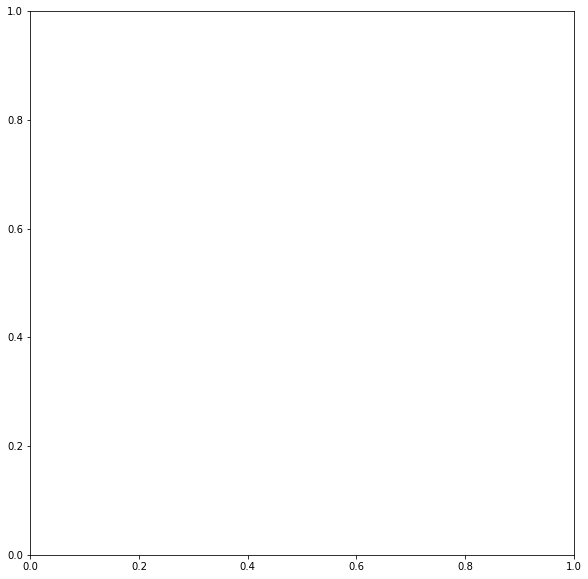

In [21]:
#Debugging the mask function

## Applies a MASK to the image before segmentation
def maskFig(inpImg_,bottomMar=60,topGap=0, col=255):
    inpImg=inpImg_.copy()
    
    #topGap=100
     
    # fill polygon1
    poly = np.array(( (0, 0), (0, int(inpImg.shape[0]/2)-topGap), (inpImg.shape[0], 0)))
    rr, cc = polygon(poly[:,0], poly[:,1], inpImg.shape)
    inpImg[rr,cc] = col
    
    # fill polygon2
    poly = np.array(( (0,int(inpImg.shape[0]/2)+topGap), (0,inpImg.shape[0]), (inpImg.shape[0],inpImg.shape[1])))
    rr, cc = polygon(poly[:,0], poly[:,1], inpImg.shape)
    inpImg[rr,cc] = col

    # fill polygon3
    poly = np.array((( inpImg.shape[0]-bottomMar,0), (inpImg.shape[0],0),(inpImg.shape[0],inpImg.shape[1]), (inpImg.shape[0]-bottomMar,inpImg.shape[1]) ))
    rr, cc = polygon(poly[:,0], poly[:,1], inpImg.shape)
    inpImg[rr,cc] = col
    
    return(inpImg)


In [ ]:

                
                
                ## work throuhg the panles
                corr={}
                corr["a"]=[0,int(imgGray_.shape[0]/2),0,int(imgGray_.shape[1]/2)]
                corr["b"]=[0,int(imgGray_.shape[0]/2),int(imgGray_.shape[1]/2)+1,imgGray_.shape[1]]
                corr["c"]=[int(imgGray_.shape[0]/2)+1,imgGray_.shape[0],0,int(imgGray_.shape[1]/2)]
                corr["d"]=[int(imgGray_.shape[0]/2)+1,imgGray_.shape[0],int(imgGray_.shape[1]/2)+1,imgGray_.shape[1]]
                
                for panel in ["a","b","c","d"]:  
                    
                      if myrank==0:
                           print("\n -- Segmenting panel "+panel+" --")
                      h.write("\n -- Segmenting panel "+panel+" --\n")
                      pos=corr[panel]
                      
                      imgO=imgO_1[pos[0]:pos[1],pos[2]:pos[3],:]
                      imgGray=imgGray_[pos[0]:pos[1],pos[2]:pos[3]]
    
                      imgGray=maskFig(imgGray,bottomMargin,topGap,255); 
                      
                      tmpGray=imgGray.reshape(-1)     # tmp image is used to only run the RFC on relavant pixels (within the MASK)
                      indx=np.argwhere(tmpGray<255)
                      
                      
                      if myrank==0:
                           print(" Generating features, please wait")
                      h.write("\n Generating features, please wait\n")
                      X_=ftGenerator(tmpGray[indx,], nGaussianFilters, nMedianFilters)   #generate features only for the pixels wthin the mask
                      
                      if myrank==0:
                           print(" Running the randomforest flassifier")
                      h.write("\n Running the randomforest flassifier\n")
                      results=RFC_model.predict(X_)
                      #results=RFC_model.predict_proba(X_); 
                 
                      results=results.reshape(tmpGray[indx,].shape)
                      tmpGray[tmpGray>0]=0
                      tmpGray[indx,]=results 
                      
                      tmpGray=tmpGray.reshape(imgGray.shape)


 -- Segmenting panel b --


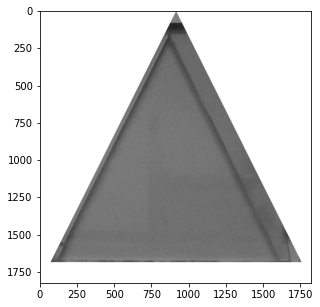

In [5]:
imgFile=imFiles[0]
imgO_1=cv2.imread(pathIMG+imgFile)
imgGray_=cv2.cvtColor(imgO_1, cv2.COLOR_BGR2GRAY)
                
corr={}
corr["a"]=[0,int(imgGray_.shape[0]/2),0,int(imgGray_.shape[1]/2)]
corr["b"]=[0,int(imgGray_.shape[0]/2),int(imgGray_.shape[1]/2)+1,imgGray_.shape[1]]
corr["c"]=[int(imgGray_.shape[0]/2)+1,imgGray_.shape[0],0,int(imgGray_.shape[1]/2)]
corr["d"]=[int(imgGray_.shape[0]/2)+1,imgGray_.shape[0],int(imgGray_.shape[1]/2)+1,imgGray_.shape[1]]

panel="b"     

print("\n -- Segmenting panel "+panel+" --")
pos=corr[panel]                  
imgO=imgO_1[pos[0]:pos[1],pos[2]:pos[3],:]
imgGray=imgGray_[pos[0]:pos[1],pos[2]:pos[3]]
imgGray=maskFig(imgGray,margin,255); 
showFig(imgGray,size=5)

  Gaussian filter


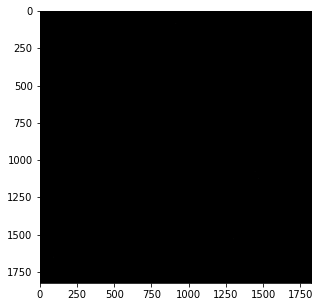

In [6]:
# Running the RFC
pathApp="/secondary/projects/mnp/tool.dev/FlyFinder_v1.0/"
pathRFC=pathApp+"RFC_model/"
    
modelFile=pathRFC+modelName+".pkl"

RFC_model=pickle.load(open(modelFile,"rb"))
    
tmpGray=imgGray.reshape(-1)     # tmp image is used to only run the RFC on relavant pixels (within the MASK)
indx=np.argwhere(tmpGray<255)

X_=ftGenerator(tmpGray[indx,], nFilters)   #generate features only for the pixels wthin the mask
                      
results=RFC_model.predict(X_)
                      #results=RFC_model.predict_proba(X_); 
results=results.reshape(tmpGray[indx,].shape)
tmpGray[tmpGray>0]=0
tmpGray[indx,]=results 
                      
tmpGray=tmpGray.reshape(imgGray.shape)
showFig(tmpGray,size=5)

In [7]:
#Dynamic segmentation
#test line 
fname_=imgFile 
imgO_=imgO 
segmented_=tmpGray
panel_=panel             
maxFlyA_=maxArea
minFlyA_=minArea
expFlies_=20

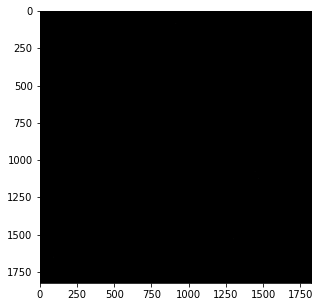

In [8]:
binary=segmented_.copy()
binary[segmented_ > 200]=1
binary[segmented_ <= 200]=0
showFig(binary,5)

 Denoising the obtained image


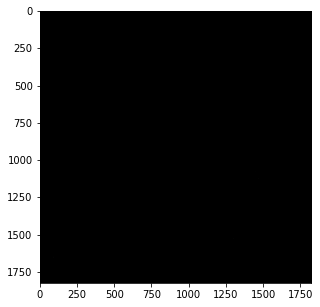

In [9]:
binaryL=label(binary,background=0) 
showFig(binaryL,size=5)
## Denoising the labeled images
print(" Denoising the obtained image")
    
smallObj=minFlyA_ #-25##+- some pixels
    
binaryL=remove_small_objects(binaryL,smallObj, connectivity=1,in_place=True)
coors_,areas_,bbox_,fimgs_=get_prop(binaryL)     

In [11]:
fname_


'harwick99_23_20.JPG'

In [ ]:
nFlies=expFlies_-len(coors)

# Get all clumped region > threshold & the number of flies expected in each region
iz=[i for i in range(len(areas_)) if areas_[i]>maxFlyA]
areas__=[];  bbox__=[];  nFlies__=[]; fimgs__=[]
for z in iz: 
    areas__.append(areas_[z])
    bbox__.append(bbox_[z])
    fimgs__.append(fimgs_[z])

In [ ]:
print("not clamped flies ",len(areas__))
print("clamped flies ",len(areas_))

In [ ]:
## Get experected number of flies in each clamped areas
for y in range(len(areas__)): 
    aFly=np.sum(areas__)/nFlies
    zFlies=int(round((areas__[y]/aFly),0))
    nFlies__.append(zFlies)

In [ ]:
print(areas__)
print("targed no of flies for each regions" ,nFlies__)

In [ ]:
### segmenting all clamped objects
for x in range(len(areas__)):
    print(" -> segmenting "+str(areas__[x])+ " pixels for "+str(nFlies__[x])+" flies")
    new_coors,new_areas= segm_clamp(fimgs__[x],bbox__[x],areas__[x],nFlies__[x])
    coors=coors+new_coors
    areas=areas+new_areas
    clmp=clmp+(len(new_areas)*[1])

In [ ]:
[519, 281, 223, 279, 322, 262, 247, 290, 234, 188, 267, 243, 237, 299, 210, 208, 353, 181, 227]

In [ ]:
areas


      
if len(coors)==expFlies_:
    outNam=writeFlies4(pname_,fname_,panel_,imgO_,coors,areas,clmp,marg_)
    print("Converged, noise cutoff "+str(smallObj)+" --> number of flies "+str(len(coors))+";  minimum area "+str(np.min(areas))+";  miximum area "+str(np.max(areas)))   
    return(outNam)
else:
    outNam=writeFlies4(pname_F,fname_,panel_,imgO_,coors,areas,clmp,marg_)
    print("Fail to detect the correct number of flies! Noise cutoff "+str(smallObj)+" --> number of flies "+str(len(coors))+";  minimum area "+str(np.min(areas))+" pxl;  miximum area "+str(np.max(areas))+" pxl")   
    return(outNam)
    


In [ ]:
expFlies_

In [ ]:
len(areas_)

In [ ]:
minFlyA_